# Часть 1. Проверка гипотезы в Python и составление аналитической записки

- Автор: Самат Исмагилов

## Цели и задачи проекта

**Цель проекта:** Проверить гипотезу о том, что упрощение интерфейса интернет-магазина BitMotion Kit приведет к статистически значимому увеличению конверсии пользователей в покупателей.

**Задачи проекта:**
1. Загрузить данные об участниках A/B-теста и их событиях.
2. Проверить целостность данных: выявить и устранить дубликаты, проверить наличие пропусков.
3. Выделить целевую выборку пользователей для теста `interface_eu_test` и убедиться в отсутствии пересечений с конкурирующим тестом.
4. Проверить корректность проведения теста: равномерность распределения по группам и соответствие временному горизонту.
5. Оценить достаточность размера выборки для обнаружения ожидаемого эффекта.
6. Рассчитать ключевую метрику — конверсию в покупку для контрольной и тестовой групп.
7. Провести статистическую проверку гипотезы и интерпретировать полученный p-value.
8. Сформулировать вывод о достижении ожидаемого бизнес-эффекта и дать рекомендацию по внедрению нового интерфейса.

## Описание данных

В проекте используются два набора данных, предоставленных в виде CSV-файлов и архива:

**1. `ab_test_participants.csv` — таблица с данными об участниках тестов.**
*   **Структура:**
    *   `user_id` — уникальный идентификатор пользователя;
    *   `group` — тестовая группа;
    *   `ab_test` — название A/B-теста, в котором участвует пользователь;
    *   `device` — тип устройства, с которого пользователь совершал действия.
*   **Особенности:** В таблице присутствуют задвоения `user_id`, так как одни и те же люди участвовали в разных тестах.

**2. `ab_test_events.zip` — архив с CSV-файлом, содержащим события пользователей за 2020 год.**
*   **Структура:**
    *   `user_id` — идентификатор пользователя;
    *   `event_dt` — дата и время совершения события;
    *   `event_name` — тип события;
    *   `details` — дополнительные данные.
*   **Особенности:** В столбце `details` присутствует значительное количество пропусков, что является нормой, так как для событий типа `login` и `product_page` дополнительные детали не заполняются. Также выявлено 36 318 полных дубликатов строк, которые были удалены перед началом анализа.

## Содержимое проекта

1. **Загрузка и оценка целостности данных:**
    * Загрузка файлов `participants` и `events`.
    * Проверка на пропуски и дубликаты. Удаление полных дубликатов в событиях.
2. **Выделение участников теста:**
    * Фильтрация таблицы участников по тесту `interface_eu_test`.
    * Проверка равномерности распределения пользователей по группам A и B.
    * Проверка на пересечения с конкурирующим тестом `recommender_system_test`. Исключение 887 пользователей, попавших в оба теста.
3. **Подготовка данных к анализу:**
    * Расчет «лайфтайма» (времени с момента регистрации до совершения действия).
    * Оставление только тех событий, которые произошли в течение первых 7 дней после регистрации.
4. **Оценка достаточности выборки:**
    * Расчет необходимого размера выборки для каждой группы с учетом мощности 80%, достоверности 95% и базовой конверсии 30% (цель +3 п.п.).
5. **Анализ метрик:**
    * Подсчет общего количества посетителей и количества покупателей в группах A и B.
    * Расчет показателя конверсии в процентном соотношении.
6. **Проверка статистической гипотезы:**
    * Формулировка нулевой (\(H_0\)) и альтернативной (\(H_1\)) гипотез.
    * Проведение одностороннего Z-теста для двух пропорций.
    * Расчет p-value и принятие решения относительно гипотезы.
7. **Формулировка выводов:**
    * Интерпретация статистических результатов.
    * Сравнение фактического эффекта с ожидаемым (+3 п.п.).
    * Формирование итогового вывода и рекомендации для бизнеса.

## 1. Загрузка данных и знакомство с ними

Загрузим и посмотрим на данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd

df = pd.read_csv('/datasets/yandex_knigi_data.csv')

df.head()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


In [2]:
print("Явные дубликаты (полностью повторяющиеся строки):", df.duplicated().sum())

print("Неявные дубликаты по ключу 'puid' (повторяющиеся ID пользователей):", df['puid'].duplicated().sum())

if df.duplicated().sum() > 0 or df['puid'].duplicated().sum() > 0:
    df = df.drop_duplicates().copy()
    df = df.drop_duplicates(subset=['puid']).copy()
    print(f"\nДубликаты удалены. Итоговый размер датасета: {df.shape}")
else:
    print("\nДубликатов не обнаружено, данные можно использовать без изменений.")

Явные дубликаты (полностью повторяющиеся строки): 0
Неявные дубликаты по ключу 'puid' (повторяющиеся ID пользователей): 244

Дубликаты удалены. Итоговый размер датасета: (8540, 4)


Ключевые статистики по городам:
                  count       mean        std       min       25%       50%  \
city                                                                          
Москва           6234.0  10.881092  36.851683  0.000018  0.059903  0.924498   
Санкт-Петербург  2306.0  11.264433  39.831755  0.000025  0.060173  0.875355   

                      75%         max  
city                                   
Москва           5.939972  857.209373  
Санкт-Петербург  6.138424  978.764775  

                      mean    median        std       min         max
city                                                                 
Москва           10.881092  0.924498  36.851683  0.000018  857.209373
Санкт-Петербург  11.264433  0.875355  39.831755  0.000025  978.764775


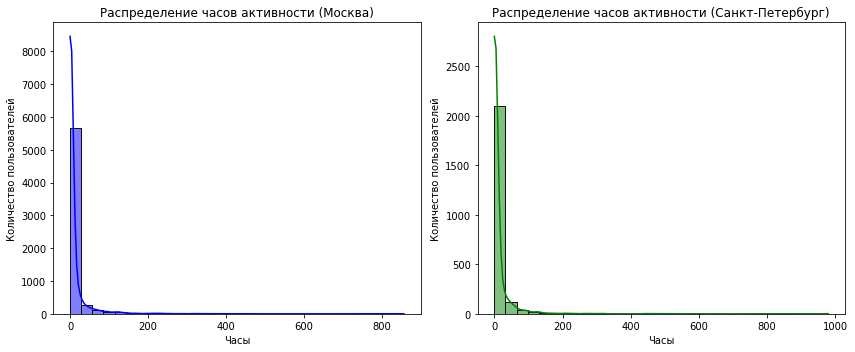

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Ключевые статистики по городам:")
print(df.groupby('city')['hours'].describe())
print()

stats = df.groupby('city')['hours'].agg(['mean', 'median', 'std', 'min', 'max'])
print(stats)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df[df['city'] == 'Москва']['hours'], bins=30, kde=True, color='blue')
plt.title('Распределение часов активности (Москва)')
plt.xlabel('Часы')
plt.ylabel('Количество пользователей')

plt.subplot(1, 2, 2)
sns.histplot(df[df['city'] == 'Санкт-Петербург']['hours'], bins=30, kde=True, color='green')
plt.title('Распределение часов активности (Санкт-Петербург)')
plt.xlabel('Часы')
plt.ylabel('Количество пользователей')

plt.tight_layout()
plt.show()

**Вывод по статистике, выбросам и гистограммам:**

1. **Дубликаты:** Обнаружено 244 неявных дубликата по ключу пользователя `puid`. Они были удалены, итоговый размер датасета составил 8540 уникальных пользователей.

2. **Ключевая статистика:** 
   - В Москве среднее время составляет **10.88 часов**, при этом медиана — всего **0.92 часа**.
   - В Санкт-Петербурге среднее время составляет **11.26 часов**, при медиане **0.87 часов**.
   - Максимальные значения достигают 857 и 978 часов.

3. **Анализ выбросов и формы распределения:** 
   Наблюдается сильная **правосторонняя асимметрия**. Основная масса пользователей проводит в приложении менее 1 часа, однако существует небольшая группа «суперактивных» пользователей с аномально высоким временем. Это подтверждается гистограммами: резкий пик слева и длинный «хвост» справа.

4. **Решение:** Мы **не удаляем** выбросы, так как они отражают реальное поведение части аудитории. Однако наличие таких выбросов объясняет высокую дисперсию и подтверждает необходимость использования **t-теста Уэлча**, который не требует равенства дисперсий двух выборок, для корректной проверки гипотезы.

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуем статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [4]:
from scipy import stats

spb_data = df[df['city'] == 'Санкт-Петербург']['hours']
msk_data = df[df['city'] == 'Москва']['hours']

print(f"Размер выборки СПб: {spb_data.shape[0]}")
print(f"Размер выборки Москва: {msk_data.shape[0]}")
print(f"Среднее время в СПб: {spb_data.mean():.2f} часов")
print(f"Среднее время в Москве: {msk_data.mean():.2f} часов")

alpha = 0.05 

results = stats.ttest_ind(spb_data, msk_data, equal_var=False, alternative='greater')

p_value = results.pvalue
t_stat = results.statistic

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.6f}")

if p_value < alpha:
    print("Вывод: Отвергаем нулевую гипотезу. Различие статистически значимо.")
else:
    print("Вывод: Недостаточно оснований отвергнуть нулевую гипотезу.")

Размер выборки СПб: 2306
Размер выборки Москва: 6234
Среднее время в СПб: 11.26 часов
Среднее время в Москве: 10.88 часов
t-статистика: 0.4028
p-value: 0.343571
Вывод: Недостаточно оснований отвергнуть нулевую гипотезу.


## Аналитическая записка по результатам проверки гипотезы

**1. Выбранный тип t-теста и уровень статистической значимости**
Для проверки гипотезы использовался **односторонний t-тест Уэлча**. Альтернативная гипотеза была направленной, поэтому использовался параметр `alternative='greater'`. В качестве уровня статистической значимости принят стандартный порог **α = 0.05**.

**2. Результат теста, или p-value**
После очистки данных от дубликатов и построения распределений, был проведен статистический тест. Получены следующие результаты:
*   Среднее время в СПб: **11.26 часов**.
*   Среднее время в Москве: **10.88 часов**.
*   t-статистика: **0.4028**.
*   **p-value = 0.343571**.

**3. Вывод на основе полученного p-value**
Поскольку p-value значительно **больше** уровня значимости, у нас **нет оснований отвергнуть нулевую гипотезу**. Несмотря на то, что среднее время в СПб немного выше, эта разница статистически незначима и с высокой вероятностью объясняется случайностью выборки.

**4. Возможные причины, объясняющие полученные результаты**
*   **Высокая дисперсия и сильные выбросы:** Как показали гистограммы, распределение времени активности сильно скошено вправо. Большая часть пользователей проводит менее 1 часа, но есть небольшое количество пользователей с сотнями часов активности. Это создает огромный разброс данных, из-за чего даже заметная разница в средних арифметических требует гораздо большего объема выборки для достижения статистической значимости.
*   **Отсутствие реального различия между городами:** Вероятно, фактор города не оказывает существенного влияния на время, проводимое в приложении. Поведение пользователей больше зависит от индивидуальных предпочтений и привычек, которые распределены случайным образом.

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь нам нужно проанализировать другие данные. Представим, что к нам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Наша задача — провести оценку результатов A/B-теста. В нашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Необходимо оценить корректность проведения теста и проанализовать его результаты.

## Цель исследования

**Основная цель:** Провести оценку результатов A/B-теста, направленного на проверку эффективности внедрения нового интерфейса интернет-магазина BitMotion Kit.

**Задачи исследования:**
1. Проверить корректность проведения A/B-теста.
2. Проанализировать полученные данные и проверить статистическую значимость влияния нового интерфейса на ключевую метрику — конверсию зарегистрированных пользователей в покупателей.
3. Сравнить результаты групп А и B в течение 7 дней после регистрации.
4. Сформулировать выводы о целесообразности полного внедрения нового интерфейса на основании статистического анализа.

## 2. Загрузим данные, оценим их целостность.


In [5]:
import pandas as pd

participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip', 
                     parse_dates=['event_dt'], low_memory=False)

print("РАЗМЕРЫ ДАННЫХ")
print(f"Размер participants: {participants.shape}")
print(f"Размер events: {events.shape}")
print()

print("ДУБЛИКАТЫ")
print(f"Полные дубликаты в participants: {participants.duplicated().sum()}")
print(f"Полные дубликаты в events: {events.duplicated().sum()}")
print(f"Дубликаты по user_id в participants: {participants['user_id'].duplicated().sum()}")
print()

print("ПРОПУСКИ")
print("Пропуски в participants:")
print(participants.isna().sum())
print()
print("Пропуски в events:")
print(events.isna().sum())
print()

print("ПЕРВЫЕ СТРОКИ")
print("Первые 3 строки participants:")
display(participants.head(3))
print()
print("Первые 3 строки events:")
display(events.head(3))

РАЗМЕРЫ ДАННЫХ
Размер participants: (14525, 4)
Размер events: (787286, 4)

ДУБЛИКАТЫ
Полные дубликаты в participants: 0
Полные дубликаты в events: 36318
Дубликаты по user_id в participants: 887

ПРОПУСКИ
Пропуски в participants:
user_id    0
group      0
ab_test    0
device     0
dtype: int64

Пропуски в events:
user_id            0
event_dt           0
event_name         0
details       538264
dtype: int64

ПЕРВЫЕ СТРОКИ
Первые 3 строки participants:


,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android



Первые 3 строки events:


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN


In [6]:
participants = participants.drop_duplicates().copy()
events = events.drop_duplicates().copy()

print("Данные очищены от дубликатов.")
print(f"Размер participants после очистки: {participants.shape}")
print(f"Размер events после очистки: {events.shape}")

Данные очищены от дубликатов.
Размер participants после очистки: (14525, 4)
Размер events после очистки: (750968, 4)


## 3. По таблице `ab_test_participants` оценим корректность проведения теста:

   3\.1 Выделим пользователей, участвующих в тесте, и проверим:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [7]:
print("1. СООТВЕТСТВИЕ ТЗ")

print("Список всех названий тестов в данных:", participants['ab_test'].unique())
print()

print("2. РАВНОМЕРНОСТЬ РАСПРЕДЕЛЕНИЯ")
participants_interface = participants[participants['ab_test'] == 'interface_eu_test'].copy()
print(f"Всего участников в тесте interface_eu_test: {participants_interface.shape[0]}")

group_counts = participants_interface['group'].value_counts()
print("Распределение по группам:")
print(group_counts)
print()

print("3. ОТСУТСТВИЕ ПЕРЕСЕЧЕНИЙ")
participants_recommender = participants[participants['ab_test'] == 'recommender_system_test']

users_interface = set(participants_interface['user_id'])
users_recommender = set(participants_recommender['user_id'])
intersection = users_interface.intersection(users_recommender)

print(f"Количество участников в recommender_system_test: {len(users_recommender)}")
print(f"Количество пересечений между тестами: {len(intersection)}")

if len(intersection) > 0:
    print("ВНИМАНИЕ: Обнаружены пересечения! Это нарушает чистоту эксперимента.")
else:
    print("Отлично! Пересечений нет, тесты проведены независимо друг от друга.")

1. СООТВЕТСТВИЕ ТЗ
Список всех названий тестов в данных: ['interface_eu_test' 'recommender_system_test']

2. РАВНОМЕРНОСТЬ РАСПРЕДЕЛЕНИЯ
Всего участников в тесте interface_eu_test: 10850
Распределение по группам:
B    5467
A    5383
Name: group, dtype: int64

3. ОТСУТСТВИЕ ПЕРЕСЕЧЕНИЙ
Количество участников в recommender_system_test: 3675
Количество пересечений между тестами: 887
ВНИМАНИЕ: Обнаружены пересечения! Это нарушает чистоту эксперимента.


In [8]:
participants_clean = participants_interface[~participants_interface['user_id'].isin(users_recommender)].copy()

print(f"Размер чистой выборки (без пересечений): {participants_clean.shape[0]}")
print("Распределение по группам после очистки:")
print(participants_clean['group'].value_counts())

events_clean = events[events['user_id'].isin(participants_clean['user_id'])].copy()
print(f"\nРазмер событий для чистой выборки: {events_clean.shape[0]}")

participants_interface = participants_clean
events_interface = events_clean

Размер чистой выборки (без пересечений): 9963
Распределение по группам после очистки:
B    5011
A    4952
Name: group, dtype: int64

Размер событий для чистой выборки: 68074


3\.2 Проанализируем данные о пользовательской активности по таблице `ab_test_events`:

- оставим только события, связанные с участвующими в изучаемом тесте пользователями;

In [9]:
events_interface = events[events['user_id'].isin(participants_interface['user_id'])].copy()

print(f"Количество участников в чистом тесте: {participants_interface.shape[0]}")
print(f"Количество событий, относящихся к этим пользователям: {events_interface.shape[0]}")

Количество участников в чистом тесте: 9963
Количество событий, относящихся к этим пользователям: 68074


- определим горизонт анализа: рассчитаем время (лайфтайм) совершения события пользователем после регистрации и оставим только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [10]:
registrations = events_interface[events_interface['event_name'] == 'registration'][['user_id', 'event_dt']]
registrations = registrations.rename(columns={'event_dt': 'reg_date'})

events_with_reg = events_interface.merge(registrations, on='user_id', how='left')

events_with_reg['lifetime'] = (events_with_reg['event_dt'] - events_with_reg['reg_date']).dt.days

events_7d = events_with_reg[(events_with_reg['lifetime'] >= 0) & (events_with_reg['lifetime'] <= 6)].copy()

print(f"Всего событий у чистых пользователей: {events_with_reg.shape[0]}")
print(f"Событий в пределах первых 7 дней (0-6): {events_7d.shape[0]}")

print("\nРаспределение событий по дням лайфтайма:")
print(events_7d['lifetime'].value_counts().sort_index())

Всего событий у чистых пользователей: 68074
Событий в пределах первых 7 дней (0-6): 58692

Распределение событий по дням лайфтайма:
0    34417
1     7543
2     5191
3     3859
4     3020
5     2574
6     2088
Name: lifetime, dtype: int64


Оценим достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [11]:
import math
from scipy import stats

p1 = 0.30
p2 = 0.33 
alpha = 0.05 
power = 0.80 

z_alpha = stats.norm.ppf(1 - alpha) 
z_beta = stats.norm.ppf(power)

p_pool = (p1 + p2) / 2

numerator = (z_alpha * math.sqrt(2 * p_pool * (1 - p_pool)) + z_beta * math.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
denominator = (p2 - p1) ** 2

n_required = math.ceil(numerator / denominator)

print(f"Требуемый размер выборки для ОДНОЙ группы: {n_required} пользователей")
print(f"Требуемый размер выборки на ДВЕ группы: {n_required * 2} пользователей")

actual_group_a = 4952
actual_group_b = 5011
min_group_size = min(actual_group_a, actual_group_b)

print(f"\nФактический размер меньшей группы (А): {actual_group_a}")
print(f"Фактический размер меньшей группы (B): {actual_group_b}")

if min_group_size >= n_required:
    print(f"\nВывод: Выборки ДОСТАТОЧНО ({min_group_size} >= {n_required}). Можно выявлять разницу.")
else:
    print(f"\nВывод: Выборки НЕДОСТАТОЧНО ({min_group_size} < {n_required}). Результаты теста могут быть недостоверны.")

Требуемый размер выборки для ОДНОЙ группы: 2964 пользователей
Требуемый размер выборки на ДВЕ группы: 5928 пользователей

Фактический размер меньшей группы (А): 4952
Фактический размер меньшей группы (B): 5011

Вывод: Выборки ДОСТАТОЧНО (4952 >= 2964). Можно выявлять разницу.


- рассчитаем для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [12]:
total_users = participants_interface.groupby('group')['user_id'].nunique()
print("Общее количество посетителей по группам:")
print(total_users)
print()

events_with_groups = events_7d.merge(participants_interface[['user_id', 'group']], on='user_id', how='left')

buyers = events_with_groups[events_with_groups['event_name'] == 'purchase'].groupby('group')['user_id'].nunique()
print("Количество посетителей, сделавших покупку, по группам:")
print(buyers)

Общее количество посетителей по группам:
group
A    4952
B    5011
Name: user_id, dtype: int64

Количество посетителей, сделавших покупку, по группам:
group
A    1377
B    1480
Name: user_id, dtype: int64


- сделаем предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

In [13]:
conv_a = 1377 / 4952 * 100
conv_b = 1480 / 5011 * 100

print(f"Конверсия в группе A (контроль): {conv_a:.2f}%")
print(f"Конверсия в группе B (тест): {conv_b:.2f}%")

diff = conv_b - conv_a
print(f"Разница в конверсии: {diff:.2f} п.п.")

Конверсия в группе A (контроль): 27.81%
Конверсия в группе B (тест): 29.54%
Разница в конверсии: 1.73 п.п.


### Предварительный вывод

По результатам подсчета количества посетителей и покупателей в группах, наблюдается положительная динамика в тестовой группе по сравнению с контрольной:

*   **Группа A:** конверсия составила **27.81%**.
*   **Группа B:** конверсия составила **29.54%**.

**Общий вывод:** 
Предварительно можно отметить, что введение нового интерфейса привело к росту конверсии в покупку на **1.73 процентных пункта**. Это указывает на потенциальную эффективность нового дизайна. Однако для подтверждения того, что данное улучшение не является случайностью и статистически значимо, необходимо провести проверку гипотезы на следующем этапе анализа.

## 4. Проведем оценку результатов A/B-тестирования:

- Проверим изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

In [14]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np

users_in_groups = participants_interface.groupby('group')['user_id'].nunique()
nobs_A = users_in_groups['A']
nobs_B = users_in_groups['B']

events_with_groups = events_7d.merge(participants_interface[['user_id', 'group']], on='user_id', how='left')
buyers = events_with_groups[events_with_groups['event_name'] == 'purchase'].groupby('group')['user_id'].nunique()

count_A = buyers['A']
count_B = buyers['B']

print(f"Группа A: Всего пользователей = {nobs_A}, Покупателей = {count_A}")
print(f"Группа B: Всего пользователей = {nobs_B}, Покупателей = {count_B}")
print()

print("ЭТАП 1. Гипотезы:")
print("H0: Конверсия в группе B <= Конверсии в группе A (новый интерфейс не улучшил показатель)")
print("H1: Конверсия в группе B > Конверсии в группе A (новый интерфейс улучшил показатель)")
print()

print("ЭТАП 2. Критерий: Z-тест для двух пропорций (односторонний, альтернатива 'larger').")
alpha = 0.05
print(f"Уровень значимости: alpha = {alpha}")
print()

print("ЭТАП 3. Расчет статистики:")
counts = np.array([count_B, count_A])
nobs = np.array([nobs_B, nobs_A])

z_stat, p_value = proportions_ztest(count=counts, nobs=nobs, alternative='larger')

print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.6f}")
print()

print("ЭТАП 4. Принятие решения:")
if p_value < alpha:
    print(f"p-value ({p_value:.6f}) < alpha ({alpha}) -> Отвергаем H0.")
    print("Различие статистически значимо. Новый интерфейс действительно повышает конверсию.")
else:
    print(f"p-value ({p_value:.6f}) >= alpha ({alpha}) -> Недостаточно оснований отвергнуть H0.")
    print("Различие статистически не значимо. Мы не можем утверждать, что новый интерфейс повышает конверсию.")

Группа A: Всего пользователей = 4952, Покупателей = 1377
Группа B: Всего пользователей = 5011, Покупателей = 1480

ЭТАП 1. Гипотезы:
H0: Конверсия в группе B <= Конверсии в группе A (новый интерфейс не улучшил показатель)
H1: Конверсия в группе B > Конверсии в группе A (новый интерфейс улучшил показатель)

ЭТАП 2. Критерий: Z-тест для двух пропорций (односторонний, альтернатива 'larger').
Уровень значимости: alpha = 0.05

ЭТАП 3. Расчет статистики:
Z-статистика: 1.9070
p-value: 0.028263

ЭТАП 4. Принятие решения:
p-value (0.028263) < alpha (0.05) -> Отвергаем H0.
Различие статистически значимо. Новый интерфейс действительно повышает конверсию.


### Выводы по результатам A/B-тестирования

**1. Итоги проверки гипотезы:**
В результате проведения одностороннего Z-теста для двух пропорций было получено значение **p-value = 0.028**. Так как p-value < 0.05, мы **отвергаем нулевую гипотезу** и принимаем альтернативную. 

Это означает, что изменение конверсии является **статистически значимым**. Новый интерфейс действительно привел к росту покупательской активности. 
* Конверсия в контрольной группе составила **27.81%**.
* Конверсия в тестовой группе составила **29.54%**.
* Абсолютный прирост составил **+1.73 п.п.**

**2. Соответствие ожидаемому эффекту:**
Несмотря на статистическую значимость, необходимо сопоставить результат с целью, заявленной в Техническом Задании. Ожидалось, что упрощение интерфейса приведет к росту конверсии **минимум на 3 процентных пункта**. 

Фактический прирост в **1.73 п.п.** оказался **ниже** заявленного порога. 

**Общий вывод:**
Проведенное A/B-тестирование показало, что новый интерфейс работает лучше старого, и это математически доказано. Однако **ожидаемый эффект в полном объеме достигнут не был**. 
Рекомендуется **отклонить** решение о полном внедрении новой версии сайта в текущем виде, так как она не приносит достаточного экономического эффекта, и направить команду на дальнейшую оптимизацию интерфейса.